In [7]:
import numpy as np
import pandas as pd

In [8]:
df = pd.read_csv('Amazon Sale Report.csv')

C:\Users\samue\AppData\Local\Temp\ipykernel_25004\2474663059.py:1: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Amazon Sale Report.csv')


In [9]:
df.head(5)

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  object 
 2   Date                128975 non-null  object 
 3   Status              128975 non-null  object 
 4   Fulfilment          128975 non-null  object 
 5   Sales Channel       128975 non-null  object 
 6   ship-service-level  128975 non-null  object 
 7   Style               128975 non-null  object 
 8   SKU                 128975 non-null  object 
 9   Category            128975 non-null  object 
 10  Size                128975 non-null  object 
 11  ASIN                128975 non-null  object 
 12  Courier Status      122103 non-null  object 
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  object 
 15  Amount              121180 non-nul

In [11]:
df.isnull().sum()

index                     0
Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6872
Qty                       0
currency               7795
Amount                 7795
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49153
B2B                       0
fulfilled-by          89698
Unnamed: 22           49050
dtype: int64

In [12]:
df = df.drop(columns = ['ship-postal-code','Unnamed: 22','currency','ASIN','Courier Status','SKU','Style','Sales Channel ','promotion-ids','fulfilled-by','Order ID','ship-country'])


In [13]:
df

,index,Date,Status,Fulfilment,ship-service-level,Category,Size,Qty,Amount,ship-city,ship-state,B2B
0,0,04-30-22,Cancelled,Merchant,Standard,Set,S,0,647.62,MUMBAI,MAHARASHTRA,False
1,1,04-30-22,Shipped - Delivered to Buyer,Merchant,Standard,kurta,3XL,1,406.00,BENGALURU,KARNATAKA,False
2,2,04-30-22,Shipped,Amazon,Expedited,kurta,XL,1,329.00,NAVI MUMBAI,MAHARASHTRA,True
3,3,04-30-22,Cancelled,Merchant,Standard,Western Dress,L,0,753.33,PUDUCHERRY,PUDUCHERRY,False
4,4,04-30-22,Shipped,Amazon,Expedited,Top,3XL,1,574.00,CHENNAI,TAMIL NADU,False
...,...,...,...,...,...,...,...,...,...,...,...,...
128970,128970,05-31-22,Shipped,Amazon,Expedited,kurta,XL,1,517.00,HYDERABAD,TELANGANA,False
128971,128971,05-31-22,Shipped,Amazon,Expedited,Set,M,1,999.00,GURUGRAM,HARYANA,False
128972,128972,05-31-22,Shipped,Amazon,Expedited,Western Dress,XXL,1,690.00,HYDERABAD,TELANGANA,False
128973,128973,05-31-22,Shipped,Amazon,Expedited,Set,XS,1,1199.00,Halol,Gujarat,False


In [14]:
print(df['ship-state'].unique())

['MAHARASHTRA' 'KARNATAKA' 'PUDUCHERRY' 'TAMIL NADU' 'UTTAR PRADESH'
 'CHANDIGARH' 'TELANGANA' 'ANDHRA PRADESH' 'RAJASTHAN' 'DELHI' 'HARYANA'
 'ASSAM' 'JHARKHAND' 'CHHATTISGARH' 'ODISHA' 'KERALA' 'MADHYA PRADESH'
 'WEST BENGAL' 'NAGALAND' 'Gujarat' 'UTTARAKHAND' 'BIHAR'
 'JAMMU & KASHMIR' 'PUNJAB' 'HIMACHAL PRADESH' 'ARUNACHAL PRADESH'
 'MANIPUR' 'Goa' 'MEGHALAYA' 'GOA' 'TRIPURA' 'LADAKH' 'DADRA AND NAGAR'
 'SIKKIM' 'Delhi' nan 'ANDAMAN & NICOBAR ' 'Punjab' 'Rajshthan' 'Manipur'
 'rajasthan' 'Odisha' 'NL' 'Bihar' 'MIZORAM' 'punjab' 'New Delhi'
 'Rajasthan' 'Punjab/Mohali/Zirakpur' 'Puducherry' 'delhi' 'RJ'
 'Chandigarh' 'orissa' 'LAKSHADWEEP' 'goa' 'PB' 'APO' 'Arunachal Pradesh'
 'AR' 'Pondicherry' 'Sikkim' 'Arunachal pradesh' 'Nagaland' 'bihar'
 'Mizoram' 'rajsthan' 'Orissa' 'Rajsthan' 'Meghalaya']


In [15]:
df.isnull().sum()

index                    0
Date                     0
Status                   0
Fulfilment               0
ship-service-level       0
Category                 0
Size                     0
Qty                      0
Amount                7795
ship-city               33
ship-state              33
B2B                      0
dtype: int64

In [54]:
df['ship-state'] = df['ship-state'].fillna('')
df['ship-city'] = df['ship-city'].fillna('')
df['B2B'] = df['B2B'].fillna('')

In [16]:
df_grouped = df.groupby('ship-state')['Amount'].sum().reset_index().sort_values('Amount',ascending = False)
df_grouped

,ship-state,Amount
28,MAHARASHTRA,13335534.14
23,KARNATAKA,10481114.37
57,TELANGANA,6916615.65
59,UTTAR PRADESH,6816642.08
56,TAMIL NADU,6515650.11
...,...,...
68,rajsthan,521.00
3,AR,493.00
53,Rajsthan,443.00
42,PB,399.00


In [17]:
print(df['ship-state'].unique())

['MAHARASHTRA' 'KARNATAKA' 'PUDUCHERRY' 'TAMIL NADU' 'UTTAR PRADESH'
 'CHANDIGARH' 'TELANGANA' 'ANDHRA PRADESH' 'RAJASTHAN' 'DELHI' 'HARYANA'
 'ASSAM' 'JHARKHAND' 'CHHATTISGARH' 'ODISHA' 'KERALA' 'MADHYA PRADESH'
 'WEST BENGAL' 'NAGALAND' 'Gujarat' 'UTTARAKHAND' 'BIHAR'
 'JAMMU & KASHMIR' 'PUNJAB' 'HIMACHAL PRADESH' 'ARUNACHAL PRADESH'
 'MANIPUR' 'Goa' 'MEGHALAYA' 'GOA' 'TRIPURA' 'LADAKH' 'DADRA AND NAGAR'
 'SIKKIM' 'Delhi' nan 'ANDAMAN & NICOBAR ' 'Punjab' 'Rajshthan' 'Manipur'
 'rajasthan' 'Odisha' 'NL' 'Bihar' 'MIZORAM' 'punjab' 'New Delhi'
 'Rajasthan' 'Punjab/Mohali/Zirakpur' 'Puducherry' 'delhi' 'RJ'
 'Chandigarh' 'orissa' 'LAKSHADWEEP' 'goa' 'PB' 'APO' 'Arunachal Pradesh'
 'AR' 'Pondicherry' 'Sikkim' 'Arunachal pradesh' 'Nagaland' 'bihar'
 'Mizoram' 'rajsthan' 'Orissa' 'Rajsthan' 'Meghalaya']


In [18]:
state = {
    'rajasthan': 'RAJASTHAN',
    'Rajasthan': 'RAJASTHAN',
    'Rajshthan': 'RAJASTHAN',
    'rajsthan': 'RAJASTHAN',
    'Rajsthan': 'RAJASTHAN',
    'RJ': 'RAJASTHAN',
    'Delhi': 'DELHI',
    'delhi': 'DELHI',
    'New Delhi': 'DELHI',
    'Punjab': 'PUNJAB',
    'punjab': 'PUNJAB',
    'Punjab/Mohali/Zirakpur': 'PUNJAB',
    'PB': 'PUNJAB',
    'Odisha': 'ODISHA',
    'orissa': 'ODISHA',
    'Orissa': 'ODISHA',
    'Arunachal Pradesh': 'ARUNACHAL PRADESH',
    'Arunachal pradesh': 'ARUNACHAL PRADESH',
    'AR': 'ARUNACHAL PRADESH',
    'Puducherry': 'PUDUCHERRY',
    'Pondicherry': 'PUDUCHERRY',
    'Nagaland': 'NAGALAND',
    'NL': 'NAGALAND',
    'Bihar': 'BIHAR',
    'bihar': 'BIHAR',
    'Goa': 'GOA',
    'goa': 'GOA',
    'Gujarat': 'GUJARAT',
    'Manipur': 'MANIPUR',
    'Mizoram': 'MIZORAM',
    'Chandigarh': 'CHANDIGARH',
    'Sikkim': 'SIKKIM',
    'Meghalaya': 'MEGHALAYA',
}


df['ship-state'] = df['ship-state'].replace(state)
print(df['ship-state'].unique())

['MAHARASHTRA' 'KARNATAKA' 'PUDUCHERRY' 'TAMIL NADU' 'UTTAR PRADESH'
 'CHANDIGARH' 'TELANGANA' 'ANDHRA PRADESH' 'RAJASTHAN' 'DELHI' 'HARYANA'
 'ASSAM' 'JHARKHAND' 'CHHATTISGARH' 'ODISHA' 'KERALA' 'MADHYA PRADESH'
 'WEST BENGAL' 'NAGALAND' 'GUJARAT' 'UTTARAKHAND' 'BIHAR'
 'JAMMU & KASHMIR' 'PUNJAB' 'HIMACHAL PRADESH' 'ARUNACHAL PRADESH'
 'MANIPUR' 'GOA' 'MEGHALAYA' 'TRIPURA' 'LADAKH' 'DADRA AND NAGAR' 'SIKKIM'
 nan 'ANDAMAN & NICOBAR ' 'MIZORAM' 'LAKSHADWEEP' 'APO']


In [19]:
df['ship-state'] = df['ship-state'].dropna()

In [52]:
df = df[df['ship-state'] != 'APO']

In [21]:
print(df['ship-state'].unique())

['MAHARASHTRA' 'KARNATAKA' 'PUDUCHERRY' 'TAMIL NADU' 'UTTAR PRADESH'
 'CHANDIGARH' 'TELANGANA' 'ANDHRA PRADESH' 'RAJASTHAN' 'DELHI' 'HARYANA'
 'ASSAM' 'JHARKHAND' 'CHHATTISGARH' 'ODISHA' 'KERALA' 'MADHYA PRADESH'
 'WEST BENGAL' 'NAGALAND' 'GUJARAT' 'UTTARAKHAND' 'BIHAR'
 'JAMMU & KASHMIR' 'PUNJAB' 'HIMACHAL PRADESH' 'ARUNACHAL PRADESH'
 'MANIPUR' 'GOA' 'MEGHALAYA' 'TRIPURA' 'LADAKH' 'DADRA AND NAGAR' 'SIKKIM'
 nan 'ANDAMAN & NICOBAR ' 'MIZORAM' 'LAKSHADWEEP']


In [58]:
df['ship-city'] = df['ship-city'].astype(str).str.upper().str.strip()
df['ship-city'] = (
    df['ship-city']
    .str.replace(r'[^A-Z\s]', '', regex=True)  #
    .str.replace(r'\s+', ' ', regex=True)     
)
city_mapping = {
    'BANGALORE': 'BENGALURU',
    'BENGALURU CITY': 'BENGALURU',
    'BANGALORE URBAN': 'BENGALURU',
    'BANGALORE RURAL': 'BENGALURU',
    'GURGAON': 'GURUGRAM',
    'PONDICHERRY': 'PUDUCHERRY',
    'ALLAHABAD': 'PRAYAGRAJ',
    'BOMBAY': 'MUMBAI',
    'NEW MUMBAI': 'MUMBAI',
    'NAVIMUMBAI': 'NAVI MUMBAI',
    'NEW DELHI': 'DELHI',
    'N DELHI': 'DELHI'
}

df['ship-city'] = df['ship-city'].replace(city_mapping)

In [55]:
df.head(5)

,index,Date,Status,Fulfilment,ship-service-level,Category,Size,Qty,Amount,ship-city,ship-state,B2B
0,0,04-30-22,Cancelled,Merchant,Standard,Set,S,0,647.62,MUMBAI,MAHARASHTRA,False
1,1,04-30-22,Shipped,Merchant,Standard,kurta,3XL,1,406.00,BENGALURU,KARNATAKA,False
2,2,04-30-22,Shipped,Amazon,Expedited,kurta,XL,1,329.00,NAVI MUMBAI,MAHARASHTRA,True
3,3,04-30-22,Cancelled,Merchant,Standard,Western Dress,L,0,753.33,PUDUCHERRY,PUDUCHERRY,False
4,4,04-30-22,Shipped,Amazon,Expedited,Top,3XL,1,574.00,CHENNAI,TAMIL NADU,False


In [25]:
df_status_counts = df.groupby('Status')['Amount'].size().reset_index(name='Total Orders')
df_status_counts 

,Status,Total Orders
0,Cancelled,18331
1,Pending,658
2,Pending - Waiting for Pick Up,281
3,Shipped,77804
4,Shipped - Damaged,1
5,Shipped - Delivered to Buyer,28769
6,Shipped - Lost in Transit,5
7,Shipped - Out for Delivery,35
8,Shipped - Picked Up,973
9,Shipped - Rejected by Buyer,11


In [26]:
df_total_amount = df.groupby('Status')['Amount'].sum().reset_index()
df_total_amount

,Status,Amount
0,Cancelled,6919284.3
1,Pending,430271.0
2,Pending - Waiting for Pick Up,192138.0
3,Shipped,50324255.0
4,Shipped - Damaged,1136.0
5,Shipped - Delivered to Buyer,18650815.0
6,Shipped - Lost in Transit,1997.0
7,Shipped - Out for Delivery,26971.0
8,Shipped - Picked Up,661252.0
9,Shipped - Rejected by Buyer,7295.0


In [ ]:
shipy = {
    'Shipped - Delivered to Buyer': 'Shipped',
    'Shipped - Picked Up': 'Shipped',
    'Shipped - Out for Delivery': 'Shipped',
    'Pending': 'Shipped',
    'Pending - Waiting for Pick Up': 'Shipped',
    'Shipped - Rejected by Buyer': 'Returned',
    'Shipped - Returned to Seller': 'Returned',
    'Shipped - Returning to Seller': 'Returned',
    'Shipped - Rejected by Buyer': 'Returned',
    'Shipped - Damaged': 'Lost / Damaged',
    'Shipped - Lost in Transit': 'Lost / Damaged'
}
df['Status']=df['Status'].replace(shipy)
df_total_amount = df.groupby('Status')['Amount'].sum().reset_index()
df_total_amount

status_mapping = {
    '	Shipped - Rejected by Buyer': 'Returned',
    'Shipped - Returned to Seller': 'Returned',
    'Shipped - Returning to Seller': 'Returned',
    'Shipped - Rejected by Buyer': 'Returned'
}

df['Status'] = df['Status'].replace(status_mapping)
df['Status'] = df['Status'].replace({
    'Shipped - Damaged': 'Lost / Damaged',
    'Shipped - Lost in Transit': 'Lost / Damaged',
    'Shipping':'Shipped'
})

In [57]:
df_total_amount = df.groupby('Status')['Amount'].sum().reset_index()
df_total_amount

,Status,Amount
0,Cancelled,6919284.3
1,Lost / Damaged,3133.0
2,Returned,1384559.0
3,Shipped,70285702.0


In [31]:
df[df['Status'] == 'Returned']['ship-state'].value_counts().reset_index()

,ship-state,count
0,MAHARASHTRA,270
1,UTTAR PRADESH,243
2,KARNATAKA,207
3,TELANGANA,166
4,TAMIL NADU,158
5,WEST BENGAL,124
6,DELHI,106
7,ANDHRA PRADESH,98
8,KERALA,83
9,ASSAM,68


In [32]:
df[df['Status'] == 'Cancelled']['ship-state'].value_counts().reset_index()

,ship-state,count
0,MAHARASHTRA,2966
1,KARNATAKA,2245
2,TELANGANA,1634
3,UTTAR PRADESH,1604
4,TAMIL NADU,1594
5,KERALA,1175
6,DELHI,922
7,ANDHRA PRADESH,892
8,WEST BENGAL,884
9,GUJARAT,591


In [33]:
df[df['Status'].str.contains('Shipped', case=False, na=False)].groupby('ship-state')['Amount'].sum().reset_index(0).sort_values('Amount', ascending=False)

,ship-state,Amount
20,MAHARASHTRA,12054937.0
15,KARNATAKA,9522813.0
31,TELANGANA,6184512.0
33,UTTAR PRADESH,6023643.0
30,TAMIL NADU,5860646.0
8,DELHI,3981565.0
16,KERALA,3327231.0
35,WEST BENGAL,3125170.0
1,ANDHRA PRADESH,2823852.0
11,HARYANA,2602935.0


In [34]:
filtered_df = df[df['Status'].isin(['Shipped', 'Cancelled', 'Returned','Lost / Damaged'])]


state_status_summary = (
    pd.crosstab(filtered_df['ship-city'], filtered_df['Status'])
    .reset_index().sort_values('Shipped',ascending=False)
)
state_status_summary['Total_Orders'] = (
    state_status_summary['Shipped'] + 
    state_status_summary['Cancelled'] + 
    state_status_summary['Returned']
)
state_status_summary = state_status_summary.sort_values('Total_Orders', ascending=False)
state_status_summary.head(10)

Status,ship-city,Cancelled,Lost / Damaged,Returned,Shipped,Total_Orders
775,BENGALURU,1312,2,122,9781,11215
2905,HYDERABAD,1148,0,102,6824,8074
4794,MUMBAI,747,0,48,5331,6126
5392,NEW DELHI,775,0,89,4931,5795
1465,CHENNAI,738,1,64,4618,5420
6157,PUNE,499,0,54,3304,3857
3711,KOLKATA,305,0,50,2026,2381
2619,GURUGRAM,211,0,24,1633,1868
7586,THANE,239,0,22,1440,1701
4396,LUCKNOW,228,0,33,1197,1458


In [35]:
filtered_df = df[df['Status'].isin(['Shipped', 'Cancelled', 'Returned','Lost / Damaged'])]


state_status_summary = (
    pd.crosstab(filtered_df['ship-state'], filtered_df['Status'])
    .reset_index().sort_values('Shipped',ascending=False)
)
state_status_summary['Total_Orders'] = (
    state_status_summary['Shipped'] + 
    state_status_summary['Cancelled'] + 
    state_status_summary['Returned']
)

state_status_summary.head(10)

Status,ship-state,Cancelled,Lost / Damaged,Returned,Shipped,Total_Orders
20,MAHARASHTRA,2966,0,270,19024,22260
15,KARNATAKA,2245,4,207,14870,17322
30,TAMIL NADU,1594,1,158,9730,11482
31,TELANGANA,1634,0,166,9530,11330
33,UTTAR PRADESH,1604,0,243,8791,10638
8,DELHI,922,0,106,6020,7048
16,KERALA,1175,0,83,5327,6585
35,WEST BENGAL,884,0,124,4955,5963
1,ANDHRA PRADESH,892,0,98,4440,5430
10,GUJARAT,591,0,53,3837,4481


In [36]:
citys = df[df['Status'].str.contains('Shipped', case=False, na=False)].groupby('ship-city')['Amount'].sum().reset_index(0).sort_values('Amount', ascending=False)
citys

,ship-city,Amount
711,BENGALURU,6277500.0
2675,HYDERABAD,4427618.0
4411,MUMBAI,3367600.0
4952,NEW DELHI,3271997.0
1339,CHENNAI,2782866.0
...,...,...
6967,TARBHA,0.0
1488,Calicut medical college,0.0
1953,Dharuhera,0.0
543,BALAPUR MIDC,0.0


In [38]:
df_total = df.groupby('B2B')['Amount'].sum().reset_index().sort_values('Amount',ascending=False)
df_total

,B2B,Amount
0,False,78001457.51
1,True,591220.79


In [39]:
statess = df[df['Status'].str.contains('Shipped', case=False, na=False)].groupby('ship-state')['Amount'].sum().reset_index(0).sort_values('Amount', ascending=False)
statess

,ship-state,Amount
20,MAHARASHTRA,12054937.0
15,KARNATAKA,9522813.0
31,TELANGANA,6184512.0
33,UTTAR PRADESH,6023643.0
30,TAMIL NADU,5860646.0
8,DELHI,3981565.0
16,KERALA,3327231.0
35,WEST BENGAL,3125170.0
1,ANDHRA PRADESH,2823852.0
11,HARYANA,2602935.0


In [40]:
df['Category'].unique()

array(['Set', 'kurta', 'Western Dress', 'Top', 'Ethnic Dress', 'Bottom',
       'Saree', 'Blouse', 'Dupatta'], dtype=object)

In [41]:
df_category=df.groupby('Category')['Amount'].sum().reset_index().sort_values('Amount',ascending=False)
df_category

,Category,Amount
5,Set,39204124.03
8,kurta,21299546.70
7,Western Dress,11216072.69
6,Top,5347792.30
3,Ethnic Dress,791217.66
0,Blouse,458408.18
1,Bottom,150667.98
4,Saree,123933.76
2,Dupatta,915.00


In [42]:
filtered_df = df[df['Category'].isin(['Set', 'kurta', 'Western Dress', 'Top', 'Ethnic Dress', 'Bottom',
       'Saree', 'Blouse', 'Dupatta']) & df['Status'].str.startswith('Shipped', na=False)]


state_status_summary = (
    pd.crosstab(filtered_df['ship-state'], filtered_df['Category'])
    .reset_index().sort_values('Set',ascending=False)
)
state_status_summary.head(10)

Category,ship-state,Blouse,Bottom,Dupatta,Ethnic Dress,Saree,Set,Top,Western Dress,kurta
20,MAHARASHTRA,104,57,0,214,17,6978,2120,2407,7127
15,KARNATAKA,175,48,1,145,21,5501,1261,1934,5784
33,UTTAR PRADESH,75,28,0,75,13,4224,679,827,2870
31,TELANGANA,77,33,2,111,6,3229,546,1470,4056
30,TAMIL NADU,70,43,0,81,28,2894,605,1093,4916
8,DELHI,42,15,0,59,10,2710,735,549,1900
11,HARYANA,24,12,0,42,5,1739,540,416,1010
35,WEST BENGAL,30,23,0,44,9,1733,472,513,2131
16,KERALA,20,20,0,25,4,1579,251,1022,2406
1,ANDHRA PRADESH,30,14,0,34,2,1513,157,576,2114


In [43]:
filtered_df = df[df['Category'].isin(['Set', 'kurta', 'Western Dress', 'Top', 'Ethnic Dress', 'Bottom',
       'Saree', 'Blouse', 'Dupatta']) & df['Status'].str.startswith('Shipped', na=False)]

state_status_summarys = (
    pd.crosstab(filtered_df['ship-city'], filtered_df['Category'])
    .reset_index().sort_values('Set',ascending=False)
)
state_status_summarys.head(5) 
#the no.of people buying set in bengaluru is very high


Category,ship-city,Blouse,Bottom,Dupatta,Ethnic Dress,Saree,Set,Top,Western Dress,kurta
711,BENGALURU,125,23,1,94,14,3526,920,1347,3731
2675,HYDERABAD,60,24,0,92,5,2289,404,1070,2880
4952,NEW DELHI,36,9,0,51,8,2249,602,441,1535
4411,MUMBAI,33,22,0,67,7,1970,710,705,1817
1339,CHENNAI,36,27,0,40,5,1381,339,523,2267


If we take bengaluru and karnataka ratio on no.of orders, we see demand concentration risk

In [46]:
shipped_df = df[df['Status'].str.startswith('Shipped', na=False)]


df_category = (
    shipped_df.groupby('Category')['Amount']
    .sum()
    .reset_index()
    .sort_values('Amount', ascending=False)
)

df_category

,Category,Amount
5,Set,35031522.0
8,kurta,19080269.0
7,Western Dress,9957414.0
6,Top,4835696.0
3,Ethnic Dress,721055.0
0,Blouse,411661.0
1,Bottom,133474.0
4,Saree,113696.0
2,Dupatta,915.0


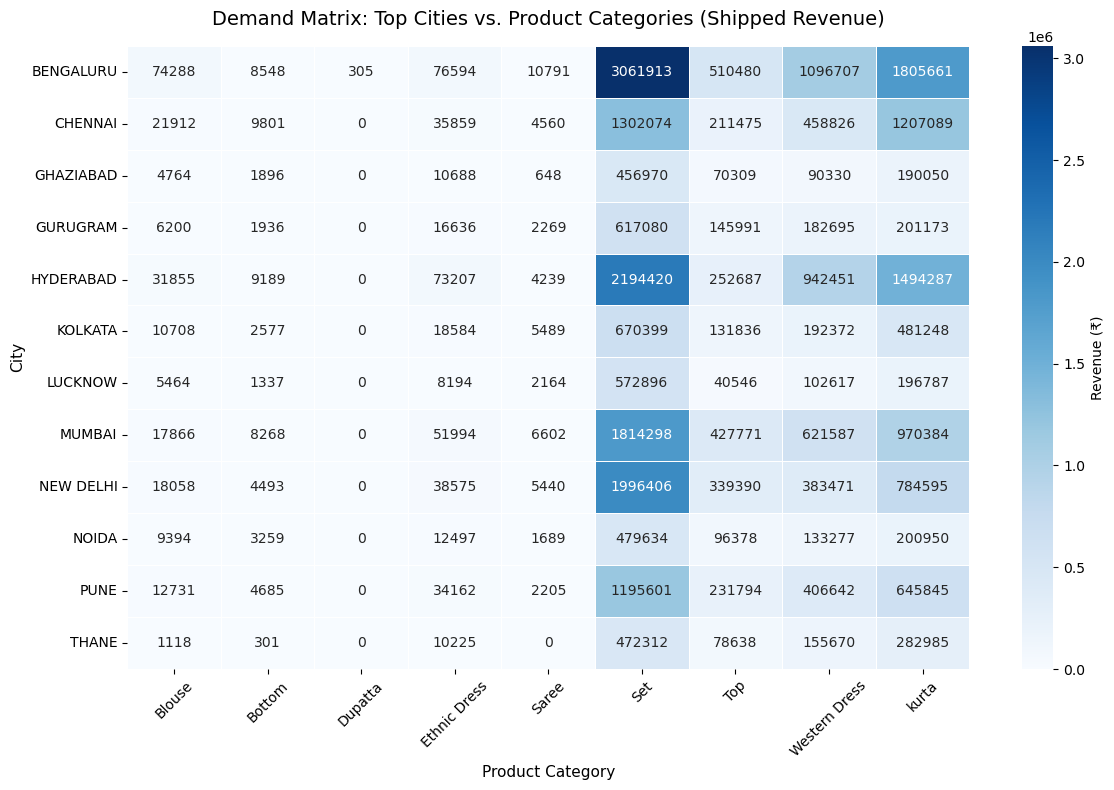

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter for shipped orders and clean city names
shipped_df = df[df['Status'].str.startswith('Shipped', na=False)].copy()
shipped_df['ship-city'] = shipped_df['ship-city'].str.upper().str.strip()

# 2. Get the top 12 cities by overall shipped volume
top_cities = shipped_df['ship-city'].value_counts().head(12).index

# 3. Filter dataset for top cities and create a pivot table (City vs Category)
heatmap_data = pd.crosstab(
    shipped_df[shipped_df['ship-city'].isin(top_cities)]['ship-city'],
    shipped_df['Category'],
    values=shipped_df['Amount'],
    aggfunc='sum'
).fillna(0)

# 4. Plot Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    heatmap_data, 
    cmap='Blues', 
    annot=True, 
    fmt='.0f', 
    linewidths=0.5,
    cbar_kws={'label': 'Revenue (₹)'}
)

plt.title('Demand Matrix: Top Cities vs. Product Categories (Shipped Revenue)', fontsize=14, pad=15)
plt.xlabel('Product Category', fontsize=11)
plt.ylabel('City', fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv('cleanAMAZON-sales.csv', index=False)

from IPython.display import FileLink


FileLink('cleanAMAZON-sales.csv')

In [60]:
df.head(5)

,index,Date,Status,Fulfilment,ship-service-level,Category,Size,Qty,Amount,ship-city,ship-state,B2B
0,0,04-30-22,Cancelled,Merchant,Standard,Set,S,0,647.62,MUMBAI,MAHARASHTRA,False
1,1,04-30-22,Shipped,Merchant,Standard,kurta,3XL,1,406.00,BENGALURU,KARNATAKA,False
2,2,04-30-22,Shipped,Amazon,Expedited,kurta,XL,1,329.00,NAVI MUMBAI,MAHARASHTRA,True
3,3,04-30-22,Cancelled,Merchant,Standard,Western Dress,L,0,753.33,PUDUCHERRY,PUDUCHERRY,False
4,4,04-30-22,Shipped,Amazon,Expedited,Top,3XL,1,574.00,CHENNAI,TAMIL NADU,False
